# Lecture 2: From tool calls to coding agents

Live demos for the slide plan in `02_lecture_plan.md`. Section numbers follow the plan's parts.

**Core message:** an agent is a loop written in ordinary code. The model only ever writes text; the harness turns
some of that text into actions and puts the results back into the context.

Two models from Lecture 1:

| Name here | Model | Runs | Used for |
| --- | --- | --- | --- |
| `aligned` | OLMo 2 1B Instruct | locally | A small model that was never trained to call tools |
| `API_MODEL` | Qwen3 30B-A3B Instruct | GWDG SAIA API | A capable model that was trained to call tools |

The database comes from `demos/nobel_lookup.py`. The steps we want to watch are
written out in the cells below.

## Setup

In [1]:
import sys, json, re
sys.path.insert(0, "..")         # the shared helpers live in ../llm_helpers.py
sys.path.insert(0, "../demos")   # the Nobel Prize database
from llm_helpers import *
from nobel_lookup import db, lookup, question
import matplotlib.pyplot as plt

aligned = load(ALIGNED)
print(DEVICE)

W1109 15:19:15.789000 68364 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/179 [00:00<?, ?it/s]

mps


In [2]:
def show_doc(parts):
    """The document, coloured by who wrote each part: yellow = the user, grey = the harness, green = the model, blue = a tool."""
    colours = {"user": "#ffe08a", "harness": "#e6e6e6", "model": "#b7f0b1", "tool": "#b3d4ff"}
    spans = "".join(f'<span style="background: {colours[who]}; color: black">{html.escape(text)}</span>' for who, text in parts)
    legend = " ".join(f'<span style="background: {c}; color: black; padding: 0 4px">{w}</span>' for w, c in colours.items())
    return HTML(f"<pre style='white-space: pre-wrap'>{spans}</pre><small>{legend}</small>")

## 0. Recap: the chat is one document

The template from Lecture 1. The model continues this text; the conversation is something a program writes.

In [3]:
print(chat_prompt(aligned.tok, "Who won the Nobel Prize in Physics in 1951?"))

<|endoftext|><|user|>
Who won the Nobel Prize in Physics in 1951?
<|assistant|>



The cliffhanger: the API model multiplies two seven-digit numbers.

In [4]:
print(ask("What is 1234567 * 7654321? Answer with the number only.", max_tokens=30))
print("correct:", 1234567 * 7654321)

9441617044537
correct: 9449772114007


## 1. Tool calling by hand

### 1.1 The deal

The system prompt describes a calculator and a format, in plain words. We write the whole chat document ourselves
(Qwen's template) and send it to the raw `/completions` endpoint, so nothing is hidden.

In [5]:
SYSTEM = ('You can use a calculator. To use it, write <tool_call>{"name": "calc", "arguments": {"expression": "..."}}'
          "</tool_call> and stop. The result will be given to you.")
QUESTION = "What is 1234567 * 7654321?"

parts = [("harness", f"<|im_start|>system\n{SYSTEM}<|im_end|>\n<|im_start|>user\n{QUESTION}<|im_end|>\n<|im_start|>assistant\n")]
doc = lambda: "".join(text for _, text in parts)
show_doc(parts)

### 1.2 The model writes the call

We tell the server to stop at `</tool_call>`: there the model hands over to us.

In [6]:
r = api(client().completions, prompt=doc(), max_tokens=200, temperature=0, stop=["</tool_call>", "<|im_end|>"])
reply = r.choices[0].text
parts.append(("model", reply))
show_doc(parts)

The model did not multiply. It wrote text in the agreed format, because that is the likely continuation
of a document that offers a calculator and asks for a product.

### 1.3 The script does the work

In [7]:
def calc(expression):
    if not re.fullmatch(r"[\d\s+\-*/().]+", expression):  # only arithmetic: never eval text from a model unchecked
        return "error: only numbers and + - * / ( ) are allowed"
    return str(eval(expression))

call = json.loads(reply.split("<tool_call>")[1])
result = calc(**call["arguments"])
print(call, "->", result)
parts.append(("harness", "</tool_call><|im_end|>\n<|im_start|>user\n<tool_response>\n"))
parts.append(("tool", result))
parts.append(("harness", "\n</tool_response><|im_end|>\n<|im_start|>assistant\n"))

r = api(client().completions, prompt=doc(), max_tokens=200, temperature=0, stop=["<|im_end|>"])
parts.append(("model", r.choices[0].text))
show_doc(parts)

{'name': 'calc', 'arguments': {'expression': '1234567 * 7654321'}} -> 9449772114007


The model wrote only the green parts. The answer is right because the model copies a number from its context.

### 1.4 Never run the model's text unchecked

`calc` (in 1.3) checks the expression before it evaluates it:

In [8]:
print(calc("2 ** 10"))
print(calc("__import__('os').system('echo hello')"))

1024
error: only numbers and + - * / ( ) are allowed


## 2. A database for the 1B model

### 2.1 Last time: the whole list

The aligned 1B model with the list of winners in its context (Lecture 1, slide 6.5). The list is read from the database
that we use below.

In [9]:
def turn(role, text):
    return f"<|{role}|>\n{text}\n"

def answer(doc, max_new_tokens=60):
    return complete(aligned, doc, max_new_tokens=max_new_tokens).split("<|endoftext|>")[0].strip()

YEARS = range(1915, 1961)

def with_list(user_question, years=YEARS):
    rows = "\n".join(f"{y}: {l}" for y, l in db.execute(
        "SELECT year, laureates FROM physics WHERE year BETWEEN ? AND ?", (years[0], years[-1])))
    return answer("<|endoftext|>" + turn("user", f"Nobel Prize winners in Physics:\n{rows}\n\n{user_question}") + "<|assistant|>\n")

print(with_list("Who won the Nobel Prize in Physics in 1951?"))
print(with_list("Who won the Nobel Prize in Physics in 1947?"))

The Nobel Prize in Physics in 1951 was awarded to John Cockcroft and Ernest T.S. Walton for their work on the production of the first artificial atoms using high-voltage electric fields. Their experiments laid the groundwork for the development of nuclear reactors and the control of nuclear reactions, which are essential


The Nobel Prize in Physics in 1947 was awarded to Wolfgang Pauli. Pauli was recognized for his contributions to the theory of atomic structure, particularly his discovery of the neutrino. The neutrino, or "little neutral one," was a particle that was hypothesized to be associated with certain


Correct for 1951: transmutation of atomic nuclei by artificially accelerated particles. 1947: Edward Appleton.

### 2.2 A database and a tool

All Physics Nobel Prizes, from the official Nobel Prize data, in a SQLite table. The tool runs one query.

In [10]:
for row in db.execute("SELECT * FROM physics WHERE year IN (1921, 1947, 1951)"):
    print(row)
print()
print(lookup("1947"))

(1921, 'Albert Einstein', 'for his services to Theoretical Physics, and especially for his discovery of the law of the photoelectric effect')
(1947, 'Edward V. Appleton', 'for his investigations of the physics of the upper atmosphere especially for the discovery of the so-called Appleton layer')
(1951, 'John Cockcroft and Ernest T.S. Walton', 'for their pioneer work on the transmutation of atomic nuclei by artificially accelerated atomic particles')

1947 | Edward V. Appleton | for his investigations of the physics of the upper atmosphere especially for the discovery of the so-called Appleton layer


### 2.3 The harness wraps your question

We ask a question, as a user would. The harness (the function below) wraps it: it puts the tool description in front,
calls the model, runs the tool call if the model writes one, and calls the model again with the result and one more
instruction. Yellow is what the user typed; everything grey was added by the harness.

In [11]:
from nobel_lookup import INSTRUCTION, ANSWER_WITH

def with_tool(user_question, show=False):
    first = "<|endoftext|><|user|>\n" + INSTRUCTION + "\n\n"
    doc = first + user_question + "\n<|assistant|>\n"
    reply = answer(doc)
    m = re.search(r"lookup\(([^)]*)\)", reply)
    if not m:  # no tool call: the reply is the answer
        if show:
            display(show_doc([("harness", first), ("user", user_question), ("harness", "\n<|assistant|>\n"), ("model", reply)]))
        return reply
    row = lookup(m.group(1))
    second = f"<|endoftext|>\n<|user|>\n{ANSWER_WITH}"
    final = answer(doc + m.group() + second + row + "\n\n" + user_question + "\n<|assistant|>\n")
    if show:
        display(show_doc([("harness", first), ("user", user_question), ("harness", "\n<|assistant|>\n"),
                          ("model", m.group()), ("harness", second), ("tool", row), ("harness", "\n\n"),
                          ("user", user_question), ("harness", "\n<|assistant|>\n"), ("model", final)]))
    return final

with_tool("Who won the Nobel Prize in Physics in 1947?", show=True);

The user typed one line. The model saw a document three times as long, and its answer is copied from the database row.
This happens whenever you ask a chat app or a coding agent something: your question is wrapped in context by the harness.

### 2.4 Does it help?

Whole list against the harness, for every year: does the answer name a laureate of that year?
This takes a few minutes (two answers per year); use a shorter range to save time.

whole list: 16 of 40 right, harness with lookup: 40 of 40 right


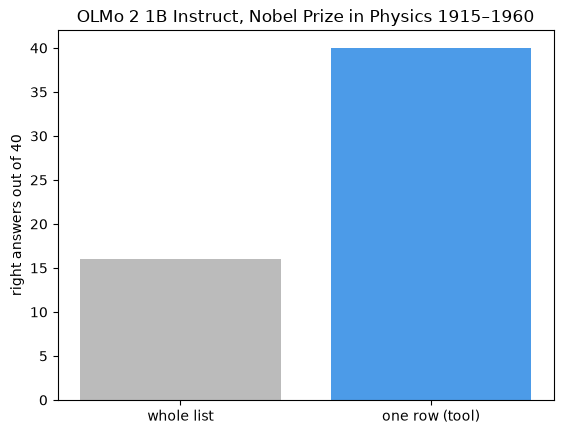

In [12]:
from nobel_lookup import surnames
results = []
for year, laureates in db.execute("SELECT year, laureates FROM physics WHERE year BETWEEN 1915 AND 1960"):
    if laureates == "not awarded":
        continue
    right = lambda text: any(s in text for s in surnames(laureates))
    results.append((year, right(with_list(question(year))), right(with_tool(question(year)))))
n = len(results)
print(f"whole list: {sum(r[1] for r in results)} of {n} right, harness with lookup: {sum(r[2] for r in results)} of {n} right")
plt.bar(["whole list", "one row (tool)"], [sum(r[1] for r in results), sum(r[2] for r in results)], color=["#bbb", "#4c9be8"])
plt.ylabel(f"right answers out of {n}")
plt.title("OLMo 2 1B Instruct, Nobel Prize in Physics 1915–1960");

### 2.5 One more sentence breaks it

The same question, with "Answer in one sentence." added by the user. The harness treats it exactly the same way.

In [13]:
with_tool("Who won the Nobel Prize in Physics in 1947? Answer in one sentence.", show=True);

No tool call: the model answers from memory, and wrongly (Brattain won in 1956, for the transistor).
How likely is `lookup` as the first token in different documents?

In [14]:
q, extra = question(1947), " Answer in one sentence."
variants = {
    "system turn, one sentence": turn("system", INSTRUCTION) + turn("user", q + extra),
    "system turn":               turn("system", INSTRUCTION) + turn("user", q),
    "user turn, one sentence":   turn("user", INSTRUCTION + "\n\n" + q + extra),
    "user turn":                 turn("user", INSTRUCTION + "\n\n" + q),
    "user turn, chained":        turn("user", INSTRUCTION + "\n\n" + q + " Look up the data first, then answer in a full sentence."),
}
lookup_id = encode(aligned, "lookup")[0, 0]
for name, head in variants.items():
    doc = "<|endoftext|>" + head + "<|assistant|>\n"
    p = next_token_probs(aligned, doc)[lookup_id].item()
    print(f"{name:27} P('lookup') = {p:7.2%}   {answer(doc, 12)!r}")

system turn, one sentence   P('lookup') =   0.00%   'The Nobel Prize in Physics in 1947 was awarded to'


system turn                 P('lookup') =   0.16%   'Albert Einstein'


user turn, one sentence     P('lookup') =   0.00%   'The Nobel Prize in Physics in 1947 was awarded to'


user turn                   P('lookup') =  96.00%   'lookup(1947)'


user turn, chained          P('lookup') =   0.31%   'The Nobel Prize in Physics in 1947 was awarded to'


Only one document makes the call likely. "Answer in one sentence." asks for an answer right away, and wins over the
tool; so does a chained instruction ("look up first, then answer…"). An instruction in a system turn is ignored: the
model card's chat format has no system block. And the chat template has no tool role: a `tool` message is dropped
without an error.

The 1B Instruct model was trained to follow instructions in a chat, not to work inside a harness. A model built for
harnesses, like the API model in Part 3, was trained on exactly these documents: tool descriptions, tool calls and
tool results.

In [15]:
print(aligned.tok.apply_chat_template([{"role": "user", "content": "hi"}, {"role": "tool", "content": "RESULT"}], tokenize=False))

<|endoftext|><|user|>
hi



### 2.6 Questions the database can't answer

The harness wraps every question in the tool instruction, whatever the user asks. Does the model still answer from
its own knowledge, or does it look something up regardless?

In [16]:
for q in ["What is the capital of Australia?", "What is 12 * 13?", "Who discovered the neutron?",
          "Who won the Nobel Prize in Chemistry in 1911?", "Write a haiku about neutrinos."]:
    doc = "<|endoftext|><|user|>\n" + INSTRUCTION + "\n\n" + q + "\n<|assistant|>\n"
    m = re.search(r"lookup\(([^)]*)\)", answer(doc))
    print(q)
    print("   call:  ", m.group() if m else "none")
    if m:
        print("   result:", lookup(m.group(1))[:90])
    print("   answer:", with_tool(q), "\n")

What is the capital of Australia?
   call:   lookup(Australia)


   result: No entry for Australia.


   answer: The capital of Australia is Canberra. 



What is 12 * 13?
   call:   lookup(12)
   result: No entry for 12.


   answer: There is no entry for 12 in the Nobel Prize in Physics database, so I cannot provide the answer to the question 12 * 13. 

Who discovered the neutron?
   call:   lookup(1931)
   result: 1931 | not awarded | 


   answer: The neutron was not awarded the Nobel Prize in Physics in 1931. 

Who won the Nobel Prize in Chemistry in 1911?
   call:   lookup(1911)
   result: 1911 | Wilhelm Wien | for his discoveries regarding the laws governing the radiation of he


   answer: Wilhelm Wien won the Nobel Prize in Chemistry in 1911 for his discoveries regarding the laws governing the radiation of heat. 



Write a haiku about neutrinos.
   call:   none


   answer: Neutrinos fly
Through space, unseen, they go
In silence they roam 



The instruction says "look up", so the model looks up, even for a capital or a product. What happens next depends on
the database's reply: sometimes the model falls back on its own knowledge, sometimes it gives up, and sometimes the
wrong row becomes the answer. Correct: Canberra, 156, James Chadwick (1932), Marie Curie (Chemistry 1911).

## 3. Native tool calling

### 3.1 The `tools` field

The same calculator as a JSON schema. The API returns a structured tool call instead of text.

In [17]:
TOOLS = [{"type": "function", "function": {
    "name": "calc", "description": "Evaluate an arithmetic expression exactly.",
    "parameters": {"type": "object", "properties": {"expression": {"type": "string"}}, "required": ["expression"]}}}]

print(json.dumps(TOOLS, indent=1))

[
 {
  "type": "function",
  "function": {
   "name": "calc",
   "description": "Evaluate an arithmetic expression exactly.",
   "parameters": {
    "type": "object",
    "properties": {
     "expression": {
      "type": "string"
     }
    },
    "required": [
     "expression"
    ]
   }
  }
 }
]


In [18]:
messages = [{"role": "user", "content": QUESTION}]
msg = api(client().chat.completions, messages=messages, tools=TOOLS, temperature=0).choices[0].message
print("content:", msg.content)
print("tool_calls:", msg.tool_calls)

content: None
tool_calls: [ChatCompletionMessageFunctionToolCall(id='chatcmpl-tool-8d74d82bc02267d6', function=Function(arguments='{"expression": "1234567 * 7654321"}', name='calc'), type='function')]


In [19]:
messages.append(msg.model_dump(exclude_none=True))
for c in msg.tool_calls:
    messages.append({"role": "tool", "tool_call_id": c.id, "content": calc(**json.loads(c.function.arguments))})
msg = api(client().chat.completions, messages=messages, tools=TOOLS, temperature=0).choices[0].message
messages.append(msg.model_dump(exclude_none=True))
print(msg.content)

The result of $ 1234567 \times 7654321 $ is $ 9,449,772,114,007 $.


### 3.2 It is the same document

The server turns `messages` and `tools` into one text document with the model's chat template. Rendered locally:

In [20]:
def show_template(messages, tools=TOOLS):
    """The document the server builds from messages and tools (Qwen's template, rendered locally)."""
    msgs = [{**m, "tool_calls": [{"type": "function", "function": {
        "name": c["function"]["name"], "arguments": json.loads(c["function"]["arguments"])}} for c in m["tool_calls"]]}
        if m.get("tool_calls") else m for m in messages]
    print(api_tokenizer().apply_chat_template(msgs, tools=tools, tokenize=False))

show_template(messages)

<|im_start|>system
# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "calc", "description": "Evaluate an arithmetic expression exactly.", "parameters": {"type": "object", "properties": {"expression": {"type": "string"}}, "required": ["expression"]}}}
</tools>

For each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:
<tool_call>
{"name": <function-name>, "arguments": <args-json-object>}
</tool_call><|im_end|>
<|im_start|>user
What is 1234567 * 7654321?<|im_end|>
<|im_start|>assistant
<tool_call>
{"name": "calc", "arguments": {"expression": "1234567 * 7654321"}}
</tool_call><|im_end|>
<|im_start|>user
<tool_response>
9449772114007
</tool_response><|im_end|>
<|im_start|>assistant
The result of $ 1234567 \times 7654321 $ is $ 9,449,772,114,007 $.<|im_end|>



Compare with section 1: a `<tool_call>` in the model's text, a `<tool_response>` in a user turn.
The server writes the tool description into the system prompt and parses the call out of the answer.

### 3.3 The loop

Call the model; if it made tool calls, run them, append the results and repeat; else it has answered.
This loop is the core of every coding agent.

In [21]:
def agent(question, tools, functions, verbose=True):
    messages = [{"role": "user", "content": question}]
    while True:
        msg = api(client().chat.completions, messages=messages, tools=tools, temperature=0).choices[0].message
        messages.append(msg.model_dump(exclude_none=True))
        if not msg.tool_calls:
            return msg.content
        for c in msg.tool_calls:
            result = functions[c.function.name](**json.loads(c.function.arguments))
            if verbose:
                print(f"  {c.function.name}({c.function.arguments}) -> {result}")
            messages.append({"role": "tool", "tool_call_id": c.id, "content": str(result)})

### 3.4 A trained model decides by itself

The API model gets the database tool. Contrast with the 1B model in 2.3.

In [22]:
LOOKUP = [{"type": "function", "function": {
    "name": "lookup", "description": "Look up the Nobel Prize in Physics of one year in a database.",
    "parameters": {"type": "object", "properties": {"year": {"type": "integer"}}, "required": ["year"]}}}]

for q in [question(1953),
          "Who won the Nobel Prize in Physics in 1951 and 1952, and for what?",
          "What is the capital of Australia?",
          "Who won the Nobel Prize in Chemistry in 1911?"]:
    print(q)
    print(agent(q, LOOKUP, {"lookup": lookup}), "\n")

Who won the Nobel Prize in Physics in 1953?


  lookup({"year": 1953}) -> 1953 | Frits Zernike | for his demonstration of the phase contrast method, especially for his invention of the phase contrast microscope


Frits Zernike won the Nobel Prize in Physics in 1953 for his demonstration of the phase contrast method, especially for his invention of the phase contrast microscope. 

Who won the Nobel Prize in Physics in 1951 and 1952, and for what?


  lookup({"year": 1951}) -> 1951 | John Cockcroft and Ernest T.S. Walton | for their pioneer work on the transmutation of atomic nuclei by artificially accelerated atomic particles
  lookup({"year": 1952}) -> 1952 | Felix Bloch and E. M. Purcell | for their development of new methods for nuclear magnetic precision measurements and discoveries in connection therewith


The Nobel Prize in Physics winners and their contributions were:

- **1951**: John Cockcroft and Ernest T.S. Walton were awarded the prize for their pioneer work on the transmutation of atomic nuclei by artificially accelerated atomic particles.

- **1952**: Felix Bloch and E. M. Purcell received the prize for their development of new methods for nuclear magnetic precision measurements and their discoveries in connection therewith. 

What is the capital of Australia?


The capital of Australia is Canberra. 

Who won the Nobel Prize in Chemistry in 1911?


The Nobel Prize in Chemistry in 1911 was awarded to Marie Curie. 



Contrast with 2.6: this model doesn't misuse the tool. For questions the tool can't answer, it answers from its own
knowledge (Canberra; Marie Curie for Chemistry 1911). In another run it refused the Chemistry question instead
("None of the available functions can provide information…"): too careful, but it still doesn't call the tool.

### 3.5 Forcing a call

APIs can force a tool call (`tool_choice="required"`), so that the harness doesn't have to trust the model to decide. Forcing is blunt:

In [23]:
msg = api(client().chat.completions, messages=[{"role": "user", "content": "What is the capital of Australia?"}],
          tools=TOOLS, tool_choice="required", temperature=0).choices[0].message
print(msg.tool_calls[0].function)

Function(arguments='{"expression": "2 + 2"}', name='calc')


## 4.–6. The harness, agents and OpenCode

The rest of the lecture runs in OpenCode, not here. `agent()` above is a complete harness: OpenCode is the same loop,
with tools that read files, edit files and run commands, and with `AGENTS.md`, skills and agents deciding what goes
into the context.

## Backup

### B.1 A small change in wording

Ask "and for what?" instead. Does the model still call the tool?

In [24]:
for year in [1917, 1927, 1947]:
    doc = "<|endoftext|>" + turn("user", INSTRUCTION + f"\n\nWho won the Nobel Prize in Physics in {year}, and for what?") + "<|assistant|>\n"
    print(year, repr(answer(doc, 20)))

1917 'The Nobel Prize in Physics for 1917 was awarded to Wilhelm Conrad Roentgen for his discovery'


1927 'The Nobel Prize in Physics in 1927 was awarded to Wilhelm Conrad Roentgen for his discovery'
1947 'lookup(1947)'


### B.2 The arguments are sampled text too

The year has to be worked out before the call. Is the call right?

In [25]:
for q in ["Who won the Nobel Prize in Physics in the year after Albert Einstein won it?",
          "Who won the Nobel Prize in Physics ten years after the transistor prize?"]:
    print(q)
    print(agent(q, LOOKUP, {"lookup": lookup}), "\n")

Who won the Nobel Prize in Physics in the year after Albert Einstein won it?
  lookup({"year": 1922}) -> 1922 | Niels Bohr | for his services in the investigation of the structure of atoms and of the radiation emanating from them


Niels Bohr won the Nobel Prize in Physics in the year after Albert Einstein won it (1922). He was awarded the prize for his services in the investigation of the structure of atoms and of the radiation emanating from them. 

Who won the Nobel Prize in Physics ten years after the transistor prize?


  lookup({"year": 1957}) -> 1957 | Chen Ning Yang and Tsung-Dao Lee | for their penetrating investigation of the so-called parity laws which has led to important discoveries regarding the elementary particles


The Nobel Prize in Physics in 1957 was awarded to Chen Ning Yang and Tsung-Dao Lee for their penetrating investigation of the so-called parity laws, which led to important discoveries regarding elementary particles. This was ten years after the 1947 Nobel Prize in Physics, which was awarded to the inventors of the transistor, John Bardeen, Walter Brattain, and William Shockley. 

